# Chapter 30: Where Is the Best Point?

*Math Class Didn't Show Its Work* by Jason Karpeles

**In this notebook you will** follow one rectangle with perimeter 20 from its first sketch to its final check, then move the boundary of a second model to see when a turning point stops counting. The best point is never best until the question says best for what, and over which inputs.

The code cells are optional reading. Every result and every picture is shown right below the cell that makes it, so you can follow along without running anything. If you do want to run a cell, change a number and see what happens: nothing here can break.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

NAVY, TEAL, GOLD, PINK, INK, GREY = "#1f3a5f", "#1b8a8a", "#d9a21b", "#c0467a", "#222222", "#888888"

def g(x, digits=4):
    """Format a number without trailing zeros."""
    s = f"{x:.{digits}f}".rstrip("0").rstrip(".")
    return "0" if s in ("-0", "") else s

def par(x):
    """Wrap negative numbers in parentheses, for substitution chains."""
    s = g(x)
    return f"({s})" if s.startswith("-") else s

def new_fig(w=7, h=4):
    fig, ax = plt.subplots(figsize=(w, h))
    ax.grid(alpha=0.25)
    return fig, ax

## Demonstration 1: One constraint, one variable

**Question.** If the perimeter must be 20, how much choice is really left?

$$y = 10 - x \qquad\qquad A(x) = xy$$

- $x$ and $y$ are the two side lengths, in units.
- The perimeter rule $2x + 2y = 20$ becomes $y = 10 - x$.
- $A(x)$ is the area in square units.

**Predict first:** if $x = 2$, what are the other side and the area? Is the area more or less than 25?

Starting value: $x = 5$.

In [2]:
x = 5
y = 10 - x
print(f"Other side: y = 10 - {x} = {y} units")
print(f"Perimeter check: 2 x {x} + 2 x {y} = {2*x} + {2*y} = {2*x + 2*y} units")
print(f"Area: A({x}) = {x} x {y} = {x*y} square units")
print(f"Physical rectangle? {'yes' if 0 < x < 10 else 'no, the shape has no width'}")
print()
print("Other menu values:")
for xx in (1, 2, 5, 10):
    yy = 10 - xx
    print(f"  x = {xx:>2}: y = 10 - {xx} = {yy}, perimeter {2*xx} + {2*yy} = {2*xx+2*yy}, area {xx} x {yy} = {xx*yy}")

Other side: y = 10 - 5 = 5 units
Perimeter check: 2 x 5 + 2 x 5 = 10 + 10 = 20 units
Area: A(5) = 5 x 5 = 25 square units
Physical rectangle? yes

Other menu values:
  x =  1: y = 10 - 1 = 9, perimeter 2 + 18 = 20, area 1 x 9 = 9
  x =  2: y = 10 - 2 = 8, perimeter 4 + 16 = 20, area 2 x 8 = 16
  x =  5: y = 10 - 5 = 5, perimeter 10 + 10 = 20, area 5 x 5 = 25
  x = 10: y = 10 - 10 = 0, perimeter 20 + 0 = 20, area 10 x 0 = 0


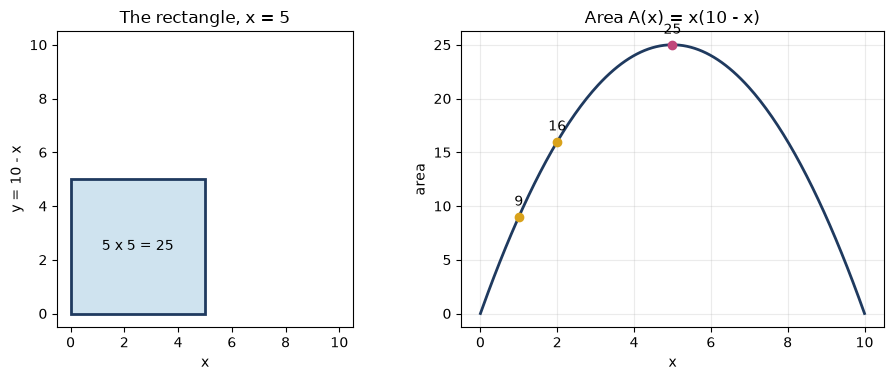

In [3]:
xs = np.linspace(0, 10, 200)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(9.5, 3.9))
x = 5; y = 10 - x
a1.add_patch(plt.Rectangle((0, 0), x, y, fc="#cfe3ef", ec=NAVY, lw=2))
a1.text(x/2, y/2, f"{x} x {y} = {x*y}", ha="center", va="center")
a1.set_xlim(-0.5, 10.5); a1.set_ylim(-0.5, 10.5); a1.set_aspect("equal")
a1.set_title("The rectangle, x = 5"); a1.set_xlabel("x"); a1.set_ylabel("y = 10 - x")
a2.plot(xs, xs*(10 - xs), color=NAVY, lw=2)
for xx in (1, 2, 5):
    a2.plot([xx], [xx*(10 - xx)], "o", color=GOLD if xx != 5 else PINK)
    a2.annotate(f"{xx*(10-xx)}", (xx, xx*(10-xx)), textcoords="offset points", xytext=(0, 8), ha="center")
a2.set_title("Area A(x) = x(10 - x)"); a2.set_xlabel("x"); a2.set_ylabel("area"); a2.grid(alpha=0.25)
plt.tight_layout(); plt.show()

**What this shows.** Once $x$ is chosen, the perimeter decides $y$ for you. The 5 by 5 square has the largest area of the three rectangles we tried (areas 9, 16 and 25). When a problem has a fixed total, write one quantity in terms of the other first, and then there is only one thing left to choose.

**Where it stops working.** A real rectangle needs $0 < x < 10$. At $x = 10$ the formula still works but the shape has no width (area 0), so the model and the story part ways.

## Demonstration 2: The derivative names a candidate

**Question.** Where does the area stop rising and start falling?

$$A'(x) = 10 - 2x$$

- $A'(x)$ is the slope of the area curve at $x$, in square units of area per unit of side.
- Positive means rising, negative means falling, zero means flat.

**Predict first:** at $x = 6$, will the tangent line tilt up or down, and what will $A'(6)$ be?

Starting value: $x = 5$.

In [4]:
A = lambda t: t*(10 - t)
x = 5
print(f"A'({x}) = 10 - 2 x {x} = 10 - {2*x} = {10 - 2*x}")
print(f"Direction near x = {x}: flat (candidate)")
print(f"Area A({x}) = {x} x {10 - x} = {A(x)}")
print()
for xx in (3, 4, 5, 6):
    s = 10 - 2*xx
    d = "rising" if s > 0 else ("falling" if s < 0 else "flat")
    print(f"  x = {xx}: A'({xx}) = 10 - 2 x {xx} = {s} ({d}); area {xx} x {10-xx} = {A(xx)}")

A'(5) = 10 - 2 x 5 = 10 - 10 = 0
Direction near x = 5: flat (candidate)
Area A(5) = 5 x 5 = 25

  x = 3: A'(3) = 10 - 2 x 3 = 4 (rising); area 3 x 7 = 21
  x = 4: A'(4) = 10 - 2 x 4 = 2 (rising); area 4 x 6 = 24
  x = 5: A'(5) = 10 - 2 x 5 = 0 (flat); area 5 x 5 = 25
  x = 6: A'(6) = 10 - 2 x 6 = -2 (falling); area 6 x 4 = 24


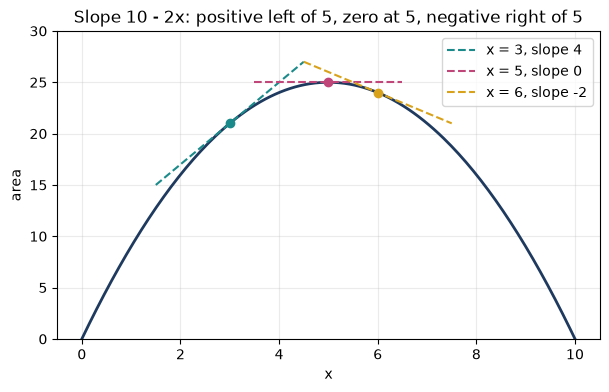

In [5]:
xs = np.linspace(0, 10, 200)
fig, ax = new_fig(7, 4)
ax.plot(xs, A(xs), color=NAVY, lw=2)
for xx, col in ((3, TEAL), (5, PINK), (6, GOLD)):
    s = 10 - 2*xx
    t = np.linspace(xx - 1.5, xx + 1.5, 20)
    ax.plot(t, A(xx) + s*(t - xx), ls="dashed", color=col, label=f"x = {xx}, slope {s}")
    ax.plot([xx], [A(xx)], "o", color=col)
ax.set_xlabel("x"); ax.set_ylabel("area"); ax.set_ylim(0, 30)
ax.set_title("Slope 10 - 2x: positive left of 5, zero at 5, negative right of 5")
ax.legend(); plt.show()

**What this shows.** The dashed line touches the curve at the chosen $x$ with slope $10 - 2x$. Left of 5 the slope is positive, right of 5 it is negative, and at 5 it is zero. A zero derivative tells you where to look: add that point to a short list, then compare values before calling anything the best.

**Where it stops working.** The slope is a local statement. $A'(4) = 2$ describes the curve near 4, not across the whole interval. And a zero slope alone does not certify a maximum.

## Demonstration 3: The completed square sets a ceiling

**Question.** Why can no rectangle in this family beat 25 square units?

$$A(x) = 25 - (x - 5)^2$$

- $(x-5)^2$ is the squared distance from 5. It is never negative, so 25 minus it is never more than 25.

**Predict first:** move 2 units away from 5. Which two inputs share an area, and what is it?

Starting value: distance 1 from 5.

In [6]:
d = 1
lo, hi = 5 - d, 5 + d
print(f"Inputs: {lo} and {hi}")
print(f"Squared distance: {d}^2 = {d**2}")
print(f"Area: 25 - {d**2} = {25 - d**2} square units")
print(f"A({lo}) = 25 - ({lo} - 5)^2 = 25 - {(lo-5)**2} = {25 - (lo-5)**2}")
print(f"A({hi}) = 25 - ({hi} - 5)^2 = 25 - {(hi-5)**2} = {25 - (hi-5)**2}")
print(f"Direct check: {lo} x {hi} = {lo*hi}")
print()
print("Other menu values:")
for dd in (0, 1, 2, 5):
    print(f"  distance {dd}: inputs {5-dd} and {5+dd}, area 25 - {dd}^2 = {25-dd**2}, direct {(5-dd)*(5+dd)}")

Inputs: 4 and 6
Squared distance: 1^2 = 1
Area: 25 - 1 = 24 square units
A(4) = 25 - (4 - 5)^2 = 25 - 1 = 24
A(6) = 25 - (6 - 5)^2 = 25 - 1 = 24
Direct check: 4 x 6 = 24

Other menu values:
  distance 0: inputs 5 and 5, area 25 - 0^2 = 25, direct 25
  distance 1: inputs 4 and 6, area 25 - 1^2 = 24, direct 24
  distance 2: inputs 3 and 7, area 25 - 2^2 = 21, direct 21
  distance 5: inputs 0 and 10, area 25 - 5^2 = 0, direct 0


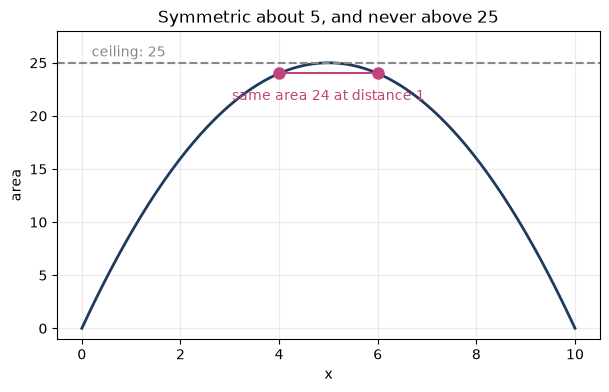

In [7]:
xs = np.linspace(0, 10, 200)
fig, ax = new_fig(7, 4)
ax.plot(xs, 25 - (xs - 5)**2, color=NAVY, lw=2)
ax.axhline(25, ls="dashed", color=GREY)
ax.text(0.2, 25.6, "ceiling: 25", color=GREY)
d = 1
for xx in (5 - d, 5 + d):
    ax.plot([xx], [25 - d**2], "o", color=PINK, ms=8)
ax.plot([5 - d, 5 + d], [25 - d**2]*2, color=PINK)
ax.text(5, 25 - d**2 - 2.5, f"same area {25-d**2} at distance {d}", ha="center", color=PINK)
ax.set_xlabel("x"); ax.set_ylabel("area"); ax.set_ylim(-1, 28)
ax.set_title("Symmetric about 5, and never above 25"); plt.show()

**What this shows.** Every input pays a penalty equal to its squared distance from 5. Inputs the same distance away pay the same penalty, so the curve is symmetric about 5. Completing the square checks the answer without derivatives: when two routes agree on 25 at $x = 5$, you can trust it more.

**Where it stops working.** The ceiling argument works because a square is never negative; it would not work for a cubic. At distance 5 the inputs are the degenerate endpoints, with area 0.

## Demonstration 4: When the turning point is off limits

**Question.** If the formula peaks at $x = 6$ but you may not use 6, where is the best point?

$$B'(x) = 12 - 2x \qquad\qquad B(x) = 36 - (x-6)^2$$

- $B(x) = 12x - x^2$ is the objective. $B'(x)$ is its slope, zero at $x = 6$.
- A square bracket includes an endpoint. A round bracket leaves it out.

**Predict first:** on the open interval $(0, 4)$, is there a largest value at all?

Starting values: right end 4, endpoints included, so the domain is $[0, 4]$.

In [8]:
B = lambda t: 12*t - t**2
right, closed = 4, True
print(f"Domain: [0, {right}]")
print(f"Is x = 6 allowed? {'yes' if 6 <= right else 'no'}")
print(f"B({right}) = 12({right}) - {right}^2 = {12*right} - {right**2} = {B(right)}")
print(f"Check: B({right}) = 36 - ({right} - 6)^2 = 36 - {(right-6)**2} = {36 - (right-6)**2}")
print("B'(x) = 12 - 2x is zero at 6, outside the domain. The function keeps rising, so the largest allowed value is at the endpoint x = 4: maximum 32.")
print()
print("Other menu values:")
for r in (4, 6, 8, 10):
    for cl in (True, False):
        dom = f"[0, {r}]" if cl else f"(0, {r})"
        if r <= 6:
            peak = B(r)
            msg = f"maximum {peak} at x = {r}" if cl else f"no maximum: values approach {peak} but x = {r} is left out"
        else:
            msg = "maximum 36 at x = 6" if True else ""
        print(f"  {dom:>8}: {msg}")
print("B(4) = 32, B(6) = 36, B(8) = 32, B(10) = 20")

Domain: [0, 4]
Is x = 6 allowed? no
B(4) = 12(4) - 4^2 = 48 - 16 = 32
Check: B(4) = 36 - (4 - 6)^2 = 36 - 4 = 32
B'(x) = 12 - 2x is zero at 6, outside the domain. The function keeps rising, so the largest allowed value is at the endpoint x = 4: maximum 32.

Other menu values:
    [0, 4]: maximum 32 at x = 4
    (0, 4): no maximum: values approach 32 but x = 4 is left out
    [0, 6]: maximum 36 at x = 6
    (0, 6): no maximum: values approach 36 but x = 6 is left out
    [0, 8]: maximum 36 at x = 6
    (0, 8): maximum 36 at x = 6
   [0, 10]: maximum 36 at x = 6
   (0, 10): maximum 36 at x = 6
B(4) = 32, B(6) = 36, B(8) = 32, B(10) = 20


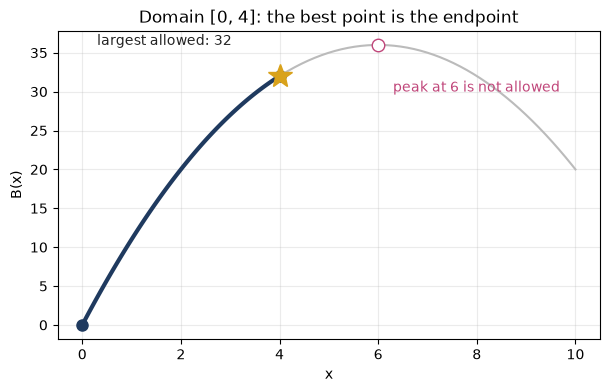

In [9]:
xs = np.linspace(0, 10, 300)
fig, ax = new_fig(7, 4)
ax.plot(xs, B(xs), color="#bbbbbb", lw=1.5)
m = xs <= 4
ax.plot(xs[m], B(xs[m]), color=NAVY, lw=3)
ax.plot([0, 4], [B(0), B(4)], "o", color=NAVY, ms=8)
ax.plot([4], [B(4)], "*", color=GOLD, ms=18, zorder=5)
ax.plot([6], [36], "o", mfc="white", mec=PINK, ms=9)
ax.annotate("peak at 6 is not allowed", (6, 36), xytext=(6.3, 30), color=PINK)
ax.annotate("largest allowed: 32", (4, 32), xytext=(0.3, 36), color=INK)
ax.set_xlabel("x"); ax.set_ylabel("B(x)")
ax.set_title("Domain [0, 4]: the best point is the endpoint"); plt.show()

**What this shows.** The solid part of the curve is the allowed domain, and the star marks the largest attained value. Write the domain beside the objective before differentiating: a turning point outside the allowed inputs is not an answer, however tidy it looks. On a closed interval the endpoints must be compared.

**Where it stops working.** On an open interval such as $(0, 4)$ the best value can be approached without ever being reached, so there is no largest value. And the formula never changes: only the allowed inputs do.

## Practice

Try each one on paper first, then open the answer to compare.

**1.** If $x = 3$, what are the other side and the area?

<details><summary>Show answer</summary>

$y = 10 - 3 = 7$, and the area is $3 \times 7 = 21$ square units.

</details>

**2.** What is $A'(3)$, and does the area rise or fall there?

<details><summary>Show answer</summary>

$A'(3) = 10 - 2 \times 3 = 4$. It is positive, so the area rises as $x$ increases near 3.

</details>

**3.** What area do $x = 1$ and $x = 9$ share?

<details><summary>Show answer</summary>

$25 - (1 - 5)^2 = 25 - 16 = 9$, and directly $1 \times 9 = 9$ square units.

</details>

**4.** On the closed interval $[0, 5]$, what is the largest value of $B(x)$?

<details><summary>Show answer</summary>

$B'(x) = 12 - 2x$ is positive on $[0, 5]$, so $B$ keeps rising and the largest is $B(5) = 36 - (5-6)^2 = 36 - 1 = 35$.

</details>